# Navier–Stokes: lid-driven cavity (PDE)

The course's second PDE benchmark: the **lid-driven cavity**, the canonical incompressible-flow test case. A square box of fluid, initially at rest, is stirred only by a lid sliding across its top. We march the primitive-variable (velocity–pressure) **Chorin projection method** from `pyutils/benchmarks/navier_stokes.py` to steady state at $\mathrm{Re}=100$, then read off the single recirculating vortex and its pressure field. Because this flow has published reference profiles, it is the standard way to *validate* an incompressible solver.

### Setup — libraries and the benchmark module

Import NumPy and Matplotlib, apply the shared course plotting style, and pull in the Navier–Stokes benchmark as `ns`. `ns.lid_driven_cavity` is the projection solver called below; nothing is computed yet.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import navier_stokes as ns

*No output — this cell only prepares the environment.* It leaves the solver `ns.lid_driven_cavity` in scope; every field below comes from a single call to it.

## Step 1 — Derive

Mass + momentum conservation for an incompressible Newtonian fluid, written in the 2-D **component form** the slides derive by a face-by-face balance on a control cell. Continuity is a *constraint*, not an evolution equation:

$$\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}=0,$$

and the two momentum balances (density scaled to $\rho=1$, so $\nu=\mu/\rho$) read

$$\frac{\partial u}{\partial t}+u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}
  =-\frac{\partial p}{\partial x}+\nu\Big(\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}\Big),$$
$$\frac{\partial v}{\partial t}+u\frac{\partial v}{\partial x}+v\frac{\partial v}{\partial y}
  =-\frac{\partial p}{\partial y}+\nu\Big(\frac{\partial^2 v}{\partial x^2}+\frac{\partial^2 v}{\partial y^2}\Big).$$

The **nonlinear convection** $u\,\partial_x u+v\,\partial_y u$ is the hard part; pressure carries no time derivative — it is a Lagrange multiplier fixed instantly by the incompressibility constraint.

## Step 2 — Write & analyze

One dimensionless number sets the regime: the **Reynolds number** $\mathrm{Re}=U L/\nu$ (inertia ÷ viscosity). Here lid speed $U_{\text{lid}}=1$ and box size $L=1$ give $\nu=U_{\text{lid}}L/\mathrm{Re}=0.01$ at $\mathrm{Re}=100$ — a laminar, single-vortex flow. Taking the divergence of the momentum equations and using continuity turns pressure into a **Poisson equation** that must be solved *every step*:

$$\frac{\partial^2 p}{\partial x^2}+\frac{\partial^2 p}{\partial y^2}
  =\frac{\rho}{\Delta t}\Big(\frac{\partial u^*}{\partial x}+\frac{\partial v^*}{\partial y}\Big).$$

That elliptic solve couples every grid node and is the dominant cost of incompressible CFD.

## Step 3 — Solve

The **Chorin projection (fractional-step) method** splits each time step into three stages:

1. **Predict** — advance momentum ignoring pressure, giving a velocity $\boldsymbol{u}^*$ that is *not* divergence-free: $u^{*}=u^{n}+\Delta t\big[-(u^n\partial_x u^n+v^n\partial_y u^n)+\nu(\partial_x^2 u^n+\partial_y^2 u^n)\big]$ (and likewise $v^{*}$).
2. **Pressure Poisson** — solve $\nabla^2 p=\tfrac{\rho}{\Delta t}\,\nabla\!\cdot\boldsymbol{u}^*$ with `nit=50` Jacobi sweeps of the 5-point stencil.
3. **Correct** — project onto the divergence-free space: $\boldsymbol{u}^{n+1}=\boldsymbol{u}^{*}-\tfrac{\Delta t}{\rho}\nabla p$.

**Boundary conditions.** No-slip ($u=v=0$) on the left, right, and bottom walls; a **moving top lid** $u=U_{\text{lid}}=1,\ v=0$. Pressure is Neumann ($\partial p/\partial n=0$) on the three fixed walls with reference $p=0$ at the lid. **Initial condition:** fluid at rest, $u=v=p=0$.

**Parameters.** $41\times41$ grid on the unit square ($\Delta x=\Delta y=0.025$), $\mathrm{Re}=100$, diffusive-safe step $\Delta t=0.2\,\min(\Delta x,\Delta y)^2/\nu=0.0125$, run for `nt=400` steps ($t\approx5$) to reach steady state.

In [2]:
x, y, u, v, p = ns.lid_driven_cavity(nx=41, ny=41, nt=400, nit=50, Re=100.0)
speed = np.sqrt(u**2 + v**2)
print('max speed:', round(float(speed.max()),3))

max speed: 1.0


The solver returns the steady fields $(x,y,u,v,p)$ on the $41\times41$ grid, and prints `max speed: 1.0`. That maximum is exactly the lid speed $U_{\text{lid}}=1$: no interior fluid can move faster than the boundary that drives it, so the peak sits in the thin shear layer just under the lid while the interior recirculates at a small fraction of it. These fields feed the plot next.

## Step 4 — Analyze

Two views of the steady state: (left) flow **streamlines** drawn over the speed magnitude $|\boldsymbol{u}|=\sqrt{u^2+v^2}$, and (right) the **pressure** field. Watch for the single primary vortex with its centre pushed toward the moving lid, the faint secondary eddies in the bottom corners, and the pressure extremes at the top corners where the lid meets the walls. The figure renders inline below.

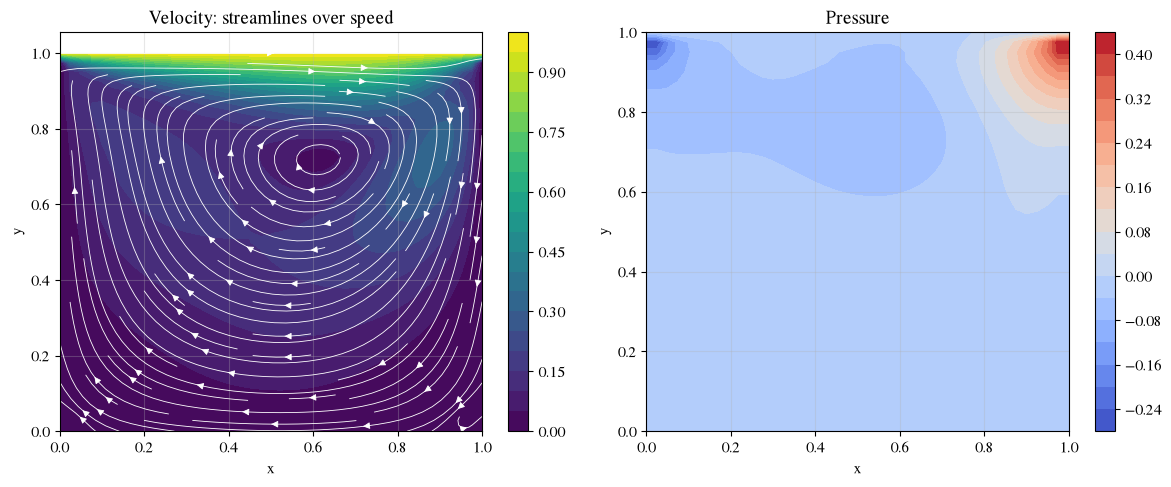

In [3]:
X, Y = np.meshgrid(x, y, indexing='ij')
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
c0 = ax[0].contourf(X, Y, speed, 20, cmap='viridis')
ax[0].streamplot(x, y, u.T, v.T, color='white', density=1.2, linewidth=0.6)
ax[0].set(title='Velocity: streamlines over speed', xlabel='x', ylabel='y'); fig.colorbar(c0, ax=ax[0])
c1 = ax[1].contourf(X, Y, p, 20, cmap='coolwarm')
ax[1].set(title='Pressure', xlabel='x', ylabel='y'); fig.colorbar(c1, ax=ax[1])
plt.tight_layout(); plt.show()

**Left panel — velocity.** One large **primary vortex** fills the cavity; its centre sits near $(x,y)\approx(0.6,0.72)$, displaced upward toward the driving lid and slightly downstream. Speed (viridis) is near zero through most of the interior and peaks in a thin bright band $|\boldsymbol{u}|\approx0.9$–$1.0$ immediately under the lid — the shear layer. Small counter-rotating **corner eddies** are just visible as hooks in the two bottom corners.

**Right panel — pressure.** Nearly uniform over the bulk, with the two signature corner singularities: a sharp high-pressure spike ($p\approx+0.4$) at the top-**right** (downstream) corner where the lid rams fluid into the wall, and a low-pressure spot ($p\approx-0.24$) at the top-**left** (upstream) corner. These corner pressures are the classic quantitative check of an incompressible solver.

**Hand-off.** The expensive ingredient here is the pressure-Poisson solve done *every* step — the cost that the Fourier Neural Operator (module 26) and reduced-order models (module 19) are built to bypass. We export the converged fields as a reference solution for those later lectures.

In [4]:
os.makedirs('../data', exist_ok=True)
np.savez('../data/cavity_reference.npz', x=x, y=y, u=u, v=v, p=p, Re=100.0)
print('saved ../data/cavity_reference.npz')

saved ../data/cavity_reference.npz


Writes `../data/cavity_reference.npz` containing the grid `x, y`, the velocity components `u, v`, the pressure `p`, and `Re=100.0`. This is the ground-truth field the surrogate and reduced-order notebooks load and try to reproduce at a fraction of the cost.